# Försäljningsanalys av e-handel

## Förberedelser och inläsning av data

In [85]:
import pandas as pd
import sys
from pathlib import Path

project_root = Path.cwd()

if project_root.name in ["notebooks", "reports"]:
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project folder:", project_root)
print("Data folder exists:", (project_root / "data").is_dir())

Project folder: d:\Data Scientist\ExamUppgift\ecommerce-team2\ecommerce-team2
Data folder exists: True


In [86]:
from src.io_utils import load_sales_data, get_data_quality_report

file_path = project_root / "data" / "ecommerce_sales.csv"

df = load_sales_data(file_path)

display(df.head())

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [87]:
import src.metrics
import src.viz
import importlib

importlib.reload(src.metrics)
importlib.reload(src.viz)

from src.metrics import (
    revenue_by_category,
    revenue_by_month,
    revenue_by_group,
    top_categories,
    total_revenue,
    total_units
)

from src.viz import (
    plot_revenue_by_category,
    plot_monthly_revenue
)



## Dataöversikt


In [88]:
total_intäkt = total_revenue(df)
totalt_antal_enheter = total_units(df)

print(f"Total intäkt: {total_intäkt:.2f} kr")
print(f"Totalt antal enheter: {totalt_antal_enheter}")

Total intäkt: 3502767.23 kr
Totalt antal enheter: 7463


# Datakvalitet

In [89]:
df = load_sales_data(file_path)
print("Datasets storlek:", df.shape)
display(df.head())

Datasets storlek: (2500, 7)


,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [90]:
datakavalitetsrapport = get_data_quality_report(df)
display(datakavalitetsrapport)

Antal rader               2500
Antal kolumner               7
Saknade värden               0
Helt duplicerade rader       0
Saknade order-id             0
Ogiltiga datum               0
Negativa priser              0
Negativa enheter             0
Negativ intäkt               0
Name: Resultat, dtype: int64

In [91]:
df.duplicated().sum()

np.int64(0)

In [92]:
print("Antal rader:", len(df))
print("Antal unika order:", df["order_id"].nunique())

Antal rader: 2500
Antal unika order: 2500


Datasetet innehåller 2500 rader och 2500 unika order id vilket betyder att varje rad motsvarar en unik order. Det finns inga saknade värden eller dubbletter i datan. Eftersom varje rad motsvarar en unik order kan AOV beräknas som medelvärdet av kolumnen "revenue".

# AOV 

Syftet är att beräkna genomsnittligt ordervärde (AOV) och undersöka hur mycket ordervärdena varierar.

In [93]:
aov = df["revenue"].mean()

print(f"AOV: {aov:.2f} kr")

AOV: 1401.11 kr


In [94]:
df["revenue"].describe()

count    2500.000000
mean     1401.106892
std      1166.944967
min        50.000000
25%       577.960000
50%      1088.690000
75%      1884.750000
max      9192.600000
Name: revenue, dtype: float64

AOV är 1401,11 kr medan medianen är 1088,69 kr så ordervärdena varierar relativt mycket och det tyder på att några höga ordervärden drar upp genomsnittet. Standardavvikelsen är 1166,94 kr och ordervärdena varierar mellan 50 kr och 9192,60 kr.

In [95]:
q1 = df["revenue"].quantile(0.25)
q3 = df["revenue"].quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

outliers = df[(df["revenue"] < lower_limit) | (df["revenue"] > upper_limit)]

print("Nedre gräns:", lower_limit)
print("Övre gräns:", upper_limit)
print("Antal möjliga outliers:", len(outliers))

Nedre gräns: -1382.225
Övre gräns: 3844.935
Antal möjliga outliers: 111


In [96]:
outliers.sort_values("revenue", ascending=False).head()

,order_id,date,city,category,price,units,revenue
1411,101411,2024-02-26,Stockholm,Electronics,1838.52,5,9192.60
1339,101339,2024-02-26,Göteborg,Electronics,1703.37,5,8516.85
1491,101491,2024-06-04,Västerås,Electronics,2092.53,4,8370.12
1733,101733,2024-06-05,Uppsala,Electronics,1227.73,6,7366.38
1518,101518,2024-01-12,Göteborg,Electronics,1403.69,5,7018.45


Möjliga avvikelser

De högsta ordervärdena ligger tydligt över medianen och flera av dem tillhör kategorin Electronics. Dessa höga ordervärden kan bidra till att AOV blir högre än medianen.

## Omsättning per kategori

In [100]:
df = pd.read_csv("../data/ecommerce_sales.csv")
df.columns = df.columns.str.strip()

In [101]:
import sys 
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [102]:
from src.metrics import revenue_by_group

revenue_by_category = revenue_by_group(df, "category")

display(revenue_by_category)



,category,total_revenue
0,Electronics,1364228.07
1,Sports,734653.42
2,Clothing,586744.91
3,Home,511070.87
4,Beauty,163053.97
5,Toys,143015.99


In [103]:
category_df = revenue_by_category(df)

category_fig = plot_revenue_by_category(category_df)
display(category_fig)

TypeError: 'DataFrame' object is not callable

Electronics står för högst intäkt bland kategorierna, följt av Sports och Clothing.

## Topp 3 kategorier

In [ ]:
top_3_kategorier = top_categories(df)
display(top_3_kategorier)

,category,total_revenue
0,Electronics,1364228.07
1,Sports,734653.42
2,Clothing,586744.91


Resultat

De tre kategorier som har högst total intäkt är Electronics, Sports och Clothing. Electronics har klart högst intäkt av de tre.

## Omsättning per stad

In [ ]:
revenue_by_city = revenue_by_group(df, "city")

display(revenue_by_city)

,city,total_revenue
0,Stockholm,1227201.94
1,Göteborg,859019.65
2,Malmö,567926.32
3,Uppsala,551478.42
4,Västerås,297140.90


 Stockholm är staden med högst total intäkt, följt av Göteborg och Malmö.  

## Omsättning över tid

In [ ]:
df["date"] = pd.to_datetime(df["date"])

monthly_revenue = ( 
    df.set_index("date")["revenue"]
    .resample("ME")
    .sum()
)

display(monthly_revenue)

date
2024-01-31    664083.32
2024-02-29    548462.03
2024-03-31    487602.00
2024-04-30    580194.83
2024-05-31    632165.16
2024-06-30    590259.89
Freq: ME, Name: revenue, dtype: float64

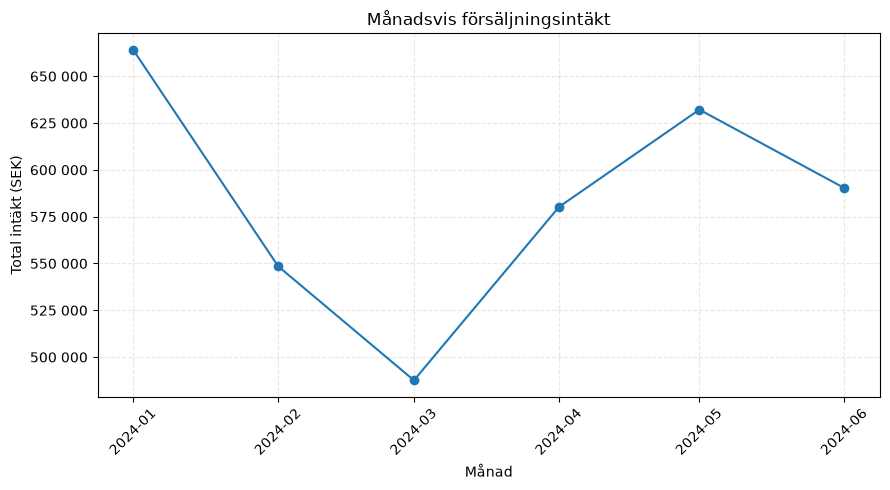

In [ ]:
monthly_df = revenue_by_month(df)

monthly_fig = plot_monthly_revenue(monthly_df)
display(monthly_fig)

Intäkten minskar från januari till mars och når periodens lägsta nivå i mars, ca 487 602kr. Därefter ökar intäkten i april och maj, innan den sjunker något i juni. Perioden är bara 6 månader, så vi kan inte avgöra om detta är ett återkommande säsongsmönster.

In [ ]:
daily_revenue = (
    df.set_index("date")["revenue"]
    .resample("D")
    .sum()
    .sort_values(ascending=False)
)

display(daily_revenue.head(10))

date
2024-02-26    45538.28
2024-04-09    39530.14
2024-06-07    38232.87
2024-01-23    33696.82
2024-04-16    32592.34
2024-05-04    32586.42
2024-01-17    32291.18
2024-05-10    32277.58
2024-01-03    30822.77
2024-05-27    30177.02
Name: revenue, dtype: float64

Den högsta dagsintäkten var den 26 februari 2024, med cirka 45 538 kr. Det är högre än övriga dagar på topp-10-listan, men vi kan inte avgöra orsaken utifrån dessa siffror ensamma.

## Viktiga resultat  

- Electronics har högst omsättning av alla produktkategorier.
- De tre största kategorierna står tillsammans för cirka 77 % av den totala omsättningen.
- Stockholm har högst omsättning av alla städer.
- Stockholm och Göteborg står tillsammans för cirka 60 % av den totala omsättningen.
- Den totala omsättningen är 3 502 767,23 kr och totalt såldes 7 463 enheter.
- Genomsnittligt ordervärde (AOV) är 1 401,11 kr.
- Medianvärdet är 1 088,69 kr, vilket är lägre än genomsnittet. Det tyder på att några order med höga värden drar upp genomsnittet.
- Standardavvikelsen är 1 166,94 kr, vilket visar att ordervärdena varierar mycket.
- Ordervärdena sträcker sig från 50 kr till 9 192,60 kr.

## Rekommendationer

## Fördjupad försäljningsanalys

In [104]:
kategori_analys = df.groupby("category").agg(
    total_intäkt=("revenue", "sum"),
    antal_sålda_enheter=("units", "sum"),
    genomsnittligt_pris=("price", "mean")
).reset_index()

kategori_analys = kategori_analys.sort_values(
    by="total_intäkt",
    ascending=False
).reset_index(drop=True)

display(kategori_analys)

,category,total_intäkt,antal_sålda_enheter,genomsnittligt_pris
0,Electronics,1364228.07,1753,789.320097
1,Sports,734653.42,1401,523.211181
2,Clothing,586744.91,1655,356.991120
3,Home,511070.87,1278,403.560959
4,Beauty,163053.97,659,250.573029
5,Toys,143015.99,717,201.582026


Vi analyserar varje produktkategori genom att beräkna total intäkt, antal sålda enheter och genomsnittligt pris. Detta hjälper oss att förstå vilka kategorier som bidrar mest till försäljningen och hur många produkter som säljs.

In [105]:
stad_analys = df.groupby("city").agg(
    total_intäkt=("revenue", "sum"),
    antal_sålda_enheter=("units", "sum"),
    genomsnittligt_order_värde=("revenue", "mean"),
    antal_order=("order_id", "nunique")
).reset_index()

stad_analys = stad_analys.sort_values(
    by="total_intäkt",
    ascending=False
).reset_index(drop=True)

display(stad_analys)

,city,total_intäkt,antal_sålda_enheter,genomsnittligt_order_värde,antal_order
0,Stockholm,1227201.94,2619,1365.074461,899
1,Göteborg,859019.65,1788,1465.903840,586
2,Malmö,567926.32,1211,1434.157374,396
3,Uppsala,551478.42,1165,1447.449921,381
4,Västerås,297140.90,680,1248.491176,238


Vi analyserar försäljningen i varje stad genom att jämföra total intäkt, antal sålda enheter, genomsnittligt ordervärde och antal ordrar. Detta hjälper oss att förstå vilka städer som har bäst försäljningsresultat.


In [106]:
stad_och_kategori = df.groupby(
    ["city", "category"]
).agg(
    total_intäkt=("revenue", "sum")
).reset_index()

stad_och_kategori = stad_och_kategori.sort_values(
    by=["city", "total_intäkt"],
    ascending=[True, False]
).reset_index(drop=True)

display(stad_och_kategori)

,city,category,total_intäkt
0,Göteborg,Electronics,340629.30
1,Göteborg,Sports,173114.39
2,Göteborg,Home,137851.89
3,Göteborg,Clothing,128566.21
4,Göteborg,Beauty,42693.20
5,Göteborg,Toys,36164.66
6,Malmö,Electronics,234714.72
7,Malmö,Sports,123529.32
8,Malmö,Home,89276.45
9,Malmö,Clothing,77554.64


Vi undersöker hur olika produktkategorier presterar i varje stad. Genom att jämföra intäkterna kan vi se vilka produktkategorier som är mest framgångsrika på olika geografiska marknader.